In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib, json, os
from sklearn.preprocessing import StandardScaler

raw = pd.read_csv("../data/features.csv")
print(raw.shape)
raw.head()

(3099, 6)


,account_id,account_age_days,trades_per_day,baseline_trades_per_day,linked_account_count,timing_regularity
0,ACC00000,213,9.15,12.96,0,0.874
1,ACC00001,394,5.27,4.38,1,0.571
2,ACC00002,41,8.72,10.97,0,1.322
3,ACC00003,604,2.67,2.28,0,0.947
4,ACC00004,374,3.71,3.43,0,1.299


In [2]:
FEATURES = ["account_age_days", "trades_per_day", "spike_ratio",
            "linked_account_count", "timing_regularity"]

def build_features(raw):
    df = raw.copy()
    # a baseline of 0 would divide by zero, so treat it as "unknown"
    baseline = df["baseline_trades_per_day"].replace(0, np.nan)
    df["spike_ratio"] = df["trades_per_day"] / baseline
    # unknown baseline -> ratio 1.0, meaning "no spike"
    df["spike_ratio"] = df["spike_ratio"].fillna(1.0)
    return df.set_index("account_id")[FEATURES]

features = build_features(raw)
features.head()

,account_age_days,trades_per_day,spike_ratio,linked_account_count,timing_regularity
account_id,,,,,
ACC00000,213,9.15,0.706019,0,0.874
ACC00001,394,5.27,1.203196,1,0.571
ACC00002,41,8.72,0.794895,0,1.322
ACC00003,604,2.67,1.171053,0,0.947
ACC00004,374,3.71,1.081633,0,1.299


In [3]:
test = pd.DataFrame({
    "account_id": [1, 2],
    "account_age_days": [5, 5],
    "trades_per_day": [10, 10],
    "baseline_trades_per_day": [0, 5],
    "linked_account_count": [0, 0],
    "timing_regularity": [1.0, 1.0],
})
print(build_features(test)["spike_ratio"])   # expect 1.0 and 2.0, no inf

print("missing values:", features.isna().sum().sum())
print("infinite values:", np.isinf(features).sum().sum())

account_id
1    1.0
2    2.0
Name: spike_ratio, dtype: float64
missing values: 0
infinite values: 0


trades_per_day: skew before = 19.48, after log = 0.69
spike_ratio: skew before = 13.99, after log = 7.91


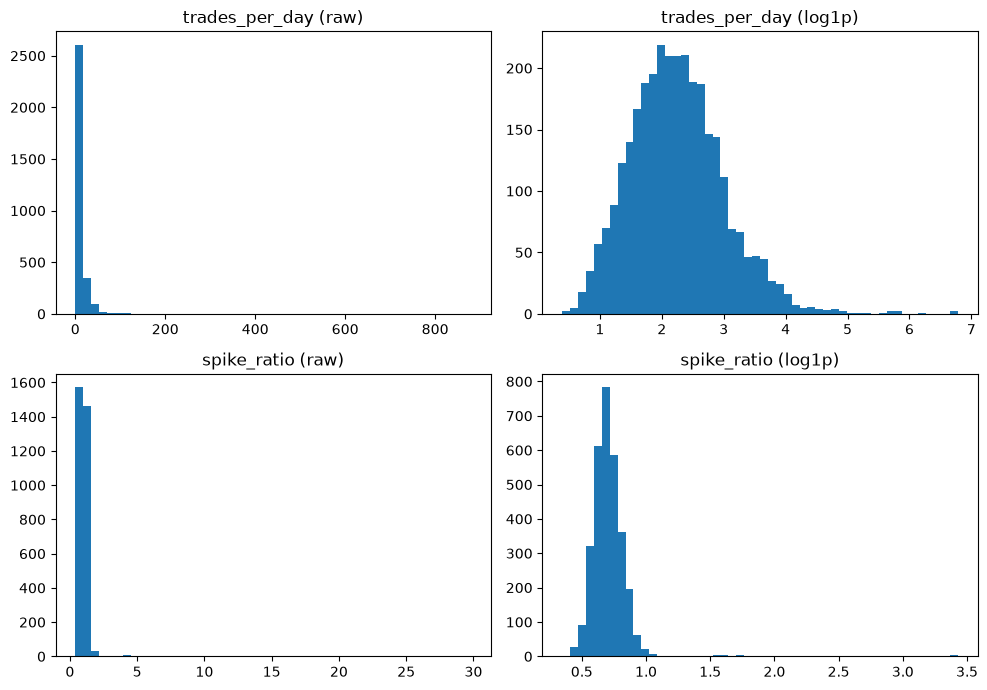

In [4]:
for col in ["trades_per_day", "spike_ratio"]:
    before = features[col].skew()
    after = np.log1p(features[col]).skew()
    print(f"{col}: skew before = {before:.2f}, after log = {after:.2f}")

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
for i, col in enumerate(["trades_per_day", "spike_ratio"]):
    axes[i, 0].hist(features[col], bins=50)
    axes[i, 0].set_title(f"{col} (raw)")
    axes[i, 1].hist(np.log1p(features[col]), bins=50)
    axes[i, 1].set_title(f"{col} (log1p)")
plt.tight_layout()
plt.show()

In [5]:
LOG_COLS = ["trades_per_day", "spike_ratio"]

after_log = features.copy()
after_log[LOG_COLS] = np.log1p(after_log[LOG_COLS])

scaler = StandardScaler()
scaled = pd.DataFrame(scaler.fit_transform(after_log),
                      index=features.index, columns=FEATURES)

os.makedirs("../artifacts", exist_ok=True)
joblib.dump(scaler, "../artifacts/scaler.pkl")
json.dump(FEATURES, open("../artifacts/feature_list.json", "w"))
scaled.to_csv("../data/feature_matrix.csv")

print(scaled.describe().loc[["mean", "std"]].round(2))

      account_age_days  trades_per_day  spike_ratio  linked_account_count  \
mean               0.0            -0.0          0.0                  -0.0   
std                1.0             1.0          1.0                   1.0   

      timing_regularity  
mean                0.0  
std                 1.0  


In [6]:
examples = {
    "highest trades/day": features["trades_per_day"].idxmax(),
    "most linked accounts": features["linked_account_count"].idxmax(),
    "lowest timing variation": features["timing_regularity"].idxmin(),
    "typical account": (features["trades_per_day"] - features["trades_per_day"].median()).abs().idxmin(),
}

for name, acc_id in examples.items():
    print(f"\n{name} (account {acc_id})")
    print(pd.DataFrame({"raw": features.loc[acc_id],
                        "scaled": scaled.loc[acc_id].round(2)}))


highest trades/day (account ACC00526)
                             raw  scaled
account_age_days        1.000000   -1.70
trades_per_day        879.690000    5.97
spike_ratio            27.997772   12.58
linked_account_count    1.000000    0.77
timing_regularity       0.980000   -0.03

most linked accounts (account ACC02593)
                             raw  scaled
account_age_days      604.000000    0.59
trades_per_day          6.660000   -0.28
spike_ratio             0.907357   -0.34
linked_account_count   12.000000   13.61
timing_regularity       1.086000    0.38

lowest timing variation (account ACC02744)
                             raw  scaled
account_age_days      591.000000    0.55
trades_per_day          4.330000   -0.76
spike_ratio             0.945415   -0.25
linked_account_count    0.000000   -0.40
timing_regularity       0.010000   -3.77

typical account (account ACC00615)
                             raw  scaled
account_age_days      166.000000   -1.07
trades_per_day      

In [7]:
scaler_loaded = joblib.load("../artifacts/scaler.pkl")
scaled_again = scaler_loaded.transform(after_log)
print("identical:", np.allclose(scaled_again, scaled.values))

identical: True


In [8]:
raw_scaled = StandardScaler().fit_transform(features[["spike_ratio"]])
log_scaled = StandardScaler().fit_transform(np.log1p(features[["spike_ratio"]]))
print("max scaled spike_ratio, no log:", raw_scaled.max().round(1))
print("max scaled spike_ratio, with log:", log_scaled.max().round(1))

max scaled spike_ratio, no log: 19.0
max scaled spike_ratio, with log: 12.9
